<a href="https://colab.research.google.com/github/Alemisa/Machine-Learning_Practical-Sessions/blob/main/Lab04_Logistic_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

* **`Lab-04: Working With Logistic Regression with weather Dataset`**

* problem: The Bureau of Meteorology wants to predict whether it will rain tomorrow (RainTomorrow = Yes) based on today's weather observations, so that farmers, event organizers, and emergency services can plan ahead.

`Step-1: Import pandas Labraries`

In [1]:
import pandas as pd

`Step-2: Load dataset`

In [2]:
dt=pd.read_csv("weather.csv")

`Step-3: Dataset description/Quck data check`

In [3]:
#1.display all dataset
dt

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RISK_MM,RainTomorrow
0,8.0,24.3,0.0,3.4,6.3,NW,30.0,SW,NW,6.0,...,29,1019.7,1015.0,7,7,14.4,23.6,No,3.6,Yes
1,14.0,26.9,3.6,4.4,9.7,ENE,39.0,E,W,4.0,...,36,1012.4,1008.4,5,3,17.5,25.7,Yes,3.6,Yes
2,13.7,23.4,3.6,5.8,3.3,NW,85.0,N,NNE,6.0,...,69,1009.5,1007.2,8,7,15.4,20.2,Yes,39.8,Yes
3,13.3,15.5,39.8,7.2,9.1,NW,54.0,WNW,W,30.0,...,56,1005.5,1007.0,2,7,13.5,14.1,Yes,2.8,Yes
4,7.6,16.1,2.8,5.6,10.6,SSE,50.0,SSE,ESE,20.0,...,49,1018.3,1018.5,7,7,11.1,15.4,Yes,0.0,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
361,9.0,30.7,0.0,7.6,12.1,NNW,76.0,SSE,NW,7.0,...,15,1016.1,1010.8,1,3,20.4,30.0,No,0.0,No
362,7.1,28.4,0.0,11.6,12.7,N,48.0,NNW,NNW,2.0,...,22,1020.0,1016.9,0,1,17.2,28.2,No,0.0,No
363,12.5,19.9,0.0,8.4,5.3,ESE,43.0,ENE,ENE,11.0,...,47,1024.0,1022.8,3,2,14.5,18.3,No,0.0,No
364,12.5,26.9,0.0,5.0,7.1,NW,46.0,SSW,WNW,6.0,...,39,1021.0,1016.2,6,7,15.8,25.9,No,0.0,No


In [4]:
#2.display head
dt.head()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RISK_MM,RainTomorrow
0,8.0,24.3,0.0,3.4,6.3,NW,30.0,SW,NW,6.0,...,29,1019.7,1015.0,7,7,14.4,23.6,No,3.6,Yes
1,14.0,26.9,3.6,4.4,9.7,ENE,39.0,E,W,4.0,...,36,1012.4,1008.4,5,3,17.5,25.7,Yes,3.6,Yes
2,13.7,23.4,3.6,5.8,3.3,NW,85.0,N,NNE,6.0,...,69,1009.5,1007.2,8,7,15.4,20.2,Yes,39.8,Yes
3,13.3,15.5,39.8,7.2,9.1,NW,54.0,WNW,W,30.0,...,56,1005.5,1007.0,2,7,13.5,14.1,Yes,2.8,Yes
4,7.6,16.1,2.8,5.6,10.6,SSE,50.0,SSE,ESE,20.0,...,49,1018.3,1018.5,7,7,11.1,15.4,Yes,0.0,No


In [5]:
#3. display the shape of dataset
dt.shape

(366, 22)

In [6]:
#4.display the information
dt.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MinTemp        366 non-null    float64
 1   MaxTemp        366 non-null    float64
 2   Rainfall       366 non-null    float64
 3   Evaporation    366 non-null    float64
 4   Sunshine       363 non-null    float64
 5   WindGustDir    363 non-null    object 
 6   WindGustSpeed  364 non-null    float64
 7   WindDir9am     335 non-null    object 
 8   WindDir3pm     365 non-null    object 
 9   WindSpeed9am   359 non-null    float64
 10  WindSpeed3pm   366 non-null    int64  
 11  Humidity9am    366 non-null    int64  
 12  Humidity3pm    366 non-null    int64  
 13  Pressure9am    366 non-null    float64
 14  Pressure3pm    366 non-null    float64
 15  Cloud9am       366 non-null    int64  
 16  Cloud3pm       366 non-null    int64  
 17  Temp9am        366 non-null    float64
 18  Temp3pm   

In [7]:
#5.describe the dataset
dt.describe()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RISK_MM
count,366.000000,366.000000,366.000000,366.000000,363.000000,364.000000,359.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000
mean,7.265574,20.550273,1.428415,4.521858,7.909366,39.840659,9.651811,17.986339,72.035519,44.519126,1019.709016,1016.810383,3.890710,4.024590,12.358470,19.230874,1.428415
std,6.025800,6.690516,4.225800,2.669383,3.481517,13.059807,7.951929,8.856997,13.137058,16.850947,6.686212,6.469422,2.956131,2.666268,5.630832,6.640346,4.225800
min,-5.300000,7.600000,0.000000,0.200000,0.000000,13.000000,0.000000,0.000000,36.000000,13.000000,996.500000,996.800000,0.000000,0.000000,0.100000,5.100000,0.000000
25%,2.300000,15.025000,0.000000,2.200000,5.950000,31.000000,6.000000,11.000000,64.000000,32.250000,1015.350000,1012.800000,1.000000,1.000000,7.625000,14.150000,0.000000
50%,7.450000,19.650000,0.000000,4.200000,8.600000,39.000000,7.000000,17.000000,72.000000,43.000000,1020.150000,1017.400000,3.500000,4.000000,12.550000,18.550000,0.000000
75%,12.500000,25.500000,0.200000,6.400000,10.500000,46.000000,13.000000,24.000000,81.000000,55.000000,1024.475000,1021.475000,7.000000,7.000000,17.000000,24.000000,0.200000
max,20.900000,35.800000,39.800000,13.800000,13.600000,98.000000,41.000000,52.000000,99.000000,96.000000,1035.700000,1033.200000,8.000000,8.000000,24.700000,34.500000,39.800000


In [8]:
#6.checking missing value
dt.isnull().sum()

,0
MinTemp,0
MaxTemp,0
Rainfall,0
Evaporation,0
Sunshine,3
WindGustDir,3
WindGustSpeed,2
WindDir9am,31
WindDir3pm,1
WindSpeed9am,7


In [10]:
# Show the distribution of values in the target column "y"
print("RainTomorrow value counts:\n", dt["RainTomorrow"].value_counts())

RainTomorrow value counts:
 RainTomorrow
No     300
Yes     66
Name: count, dtype: int64


`Step-4: Exploratory Data Analysis (brief)`

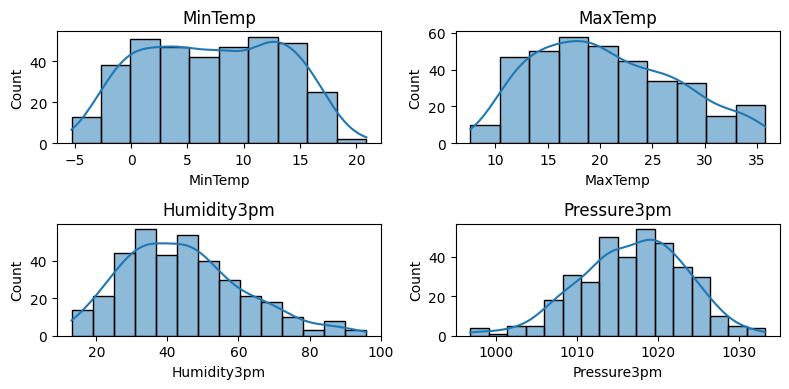

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
for i, col in enumerate(["MinTemp", "MaxTemp", "Humidity3pm", "Pressure3pm"]):
    plt.subplot(2, 2, i + 1)
    sns.histplot(dt[col].dropna(), kde=True)
    plt.title(col)
plt.tight_layout()
plt.show()

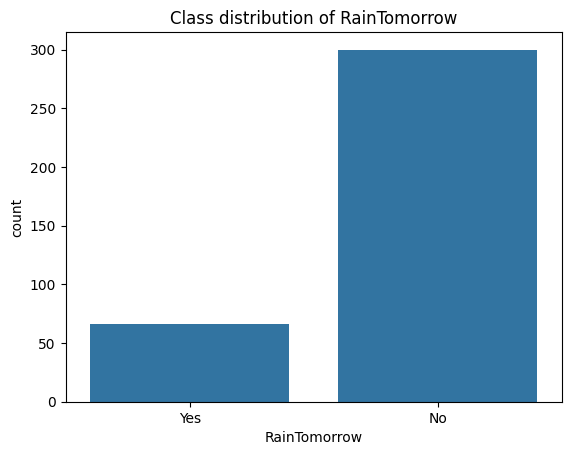

In [13]:
sns.countplot(x="RainTomorrow", data=dt)
plt.title("Class distribution of RainTomorrow")
plt.show()

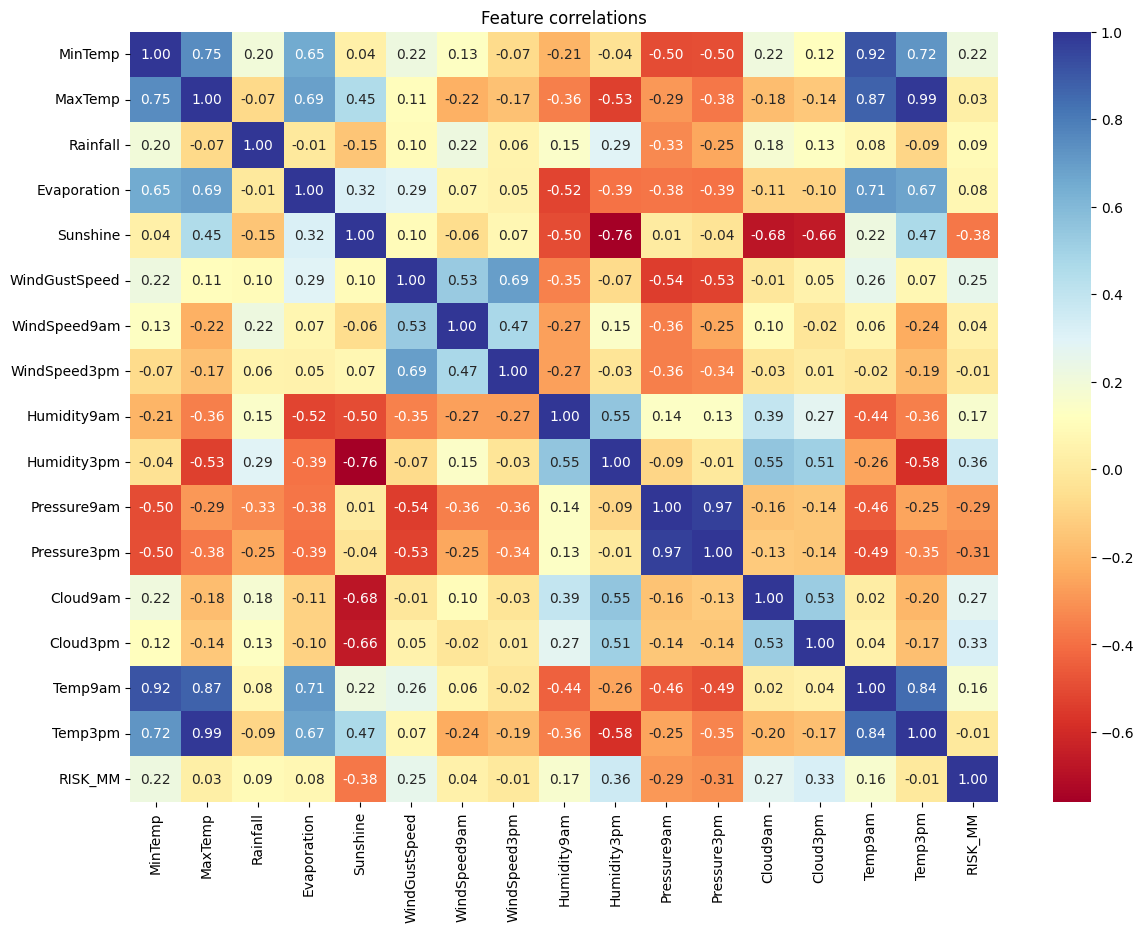

In [16]:
#correlation

plt.figure(figsize=(14, 10))
sns.heatmap(dt.corr(numeric_only=True), annot=True, fmt=".2f", cmap="RdYlBu")
plt.title("Feature correlations")
plt.show()

`Step-5: Features Selection`

In [17]:
dt = dt.drop("RISK_MM", axis=1)

X = dt.drop("RainTomorrow", axis=1)
y = dt["RainTomorrow"].map({"Yes": 1, "No": 0})

`Step-6: Split data into Train-Test Split` --> apply _stratified

In [31]:
from sklearn.model_selection import train_test_split

# This line creates X_train, X_test, y_train, and y_test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

print("Training set class ratio:\n", y_train.value_counts(normalize=True))
print("\nTesting set class ratio:\n", y_test.value_counts(normalize=True))

Training set class ratio:
 RainTomorrow
0    0.820312
1    0.179688
Name: proportion, dtype: float64

Testing set class ratio:
 RainTomorrow
0    0.818182
1    0.181818
Name: proportion, dtype: float64


`Step-6: Feature Scaling`

In [32]:
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
numeric_features     = X.select_dtypes(exclude=["object"]).columns.tolist()

print("Categorical:", categorical_features)
print("Numeric:", numeric_features)

Categorical: ['WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday']
Numeric: ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']


`Step-7: Traing the model/Logistic Regression Model`

In [36]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# 1. Define the imputers and transformers
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# 2. Combine them
preprocessor = ColumnTransformer([
    ("num", num_pipeline, numeric_features),
    ("cat", cat_pipeline, categorical_features)
])

# 3. Create the full pipeline and fit it (This handles NaNs automatically!)
clf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("clf", LogisticRegression(max_iter=2000, solver="liblinear", class_weight="balanced"))
])

clf_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['MinTemp', 'MaxTemp',
                                                   'Rainfall', 'Evaporation',
                                                   'Sunshine', 'WindGustSpeed',
                                                   'WindSpeed9am',
                                                   'WindSpeed3pm',
                                                   'Humidity9am', 'Humidity3pm',
                                                   'Pressure9am', 'Pressure3pm',
                                                   'Cloud9am', 'Cloud3pm',
                                                   'Temp9am', 'Temp3pm']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['WindGustDir', 'WindDir9am',
                                                   'WindDir3pm',
                                                   'RainToday'])])),
                ('clf',
                 LogisticRegression(class_weight='balanced', max_iter=2000,
                                    solver='liblinear'))])

In [37]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
import pandas as pd

# 1. Encode categoricals
X_train_encoded = pd.get_dummies(X_train, drop_first=True)
X_test_encoded  = pd.get_dummies(X_test,  drop_first=True)
X_test_encoded  = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

# 2. Impute missing values (NEW STEP)
imputer = SimpleImputer(strategy="median")
X_train_imputed = imputer.fit_transform(X_train_encoded)
X_test_imputed  = imputer.transform(X_test_encoded)

# 3. Scale the data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled  = scaler.transform(X_test_imputed)

# 4. Train the model
model = LogisticRegression(max_iter=1000, class_weight="balanced")
model.fit(X_train_scaled, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

`Step-8:Predictions`

In [38]:
y_pred      = model.predict(X_test_scaled)
y_pred_prob = model.predict_proba(X_test_scaled)[:, 1]

`Step-9: Preprocessing pipeline (impute, scale)`

In [39]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler",  StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, numeric_features),
    ("cat", cat_pipeline, categorical_features)
])

`Step-10: Build a pipeline combining preprocessing + classifier`

In [40]:
from sklearn.linear_model import LogisticRegression

clf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("clf", LogisticRegression(max_iter=2000, solver="liblinear", class_weight="balanced"))
])

clf_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['MinTemp', 'MaxTemp',
                                                   'Rainfall', 'Evaporation',
                                                   'Sunshine', 'WindGustSpeed',
                                                   'WindSpeed9am',
                                                   'WindSpeed3pm',
                                                   'Humidity9am', 'Humidity3pm',
                                                   'Pressure9am', 'Pressure3pm',
                                                   'Cloud9am', 'Cloud3pm',
                                                   'Temp9am', 'Temp3pm']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['WindGustDir', 'WindDir9am',
                                                   'WindDir3pm',
                                                   'RainToday'])])),
                ('clf',
                 LogisticRegression(class_weight='balanced', max_iter=2000,
                                    solver='liblinear'))])

`Step-11: Model Evaluation (metrics + confusion matrix + ROC)`

In [41]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)
import matplotlib.pyplot as plt

y_pred  = clf_pipeline.predict(X_test)
y_proba = clf_pipeline.predict_proba(X_test)[:, 1]

acc     = accuracy_score(y_test, y_pred)
prec    = precision_score(y_test, y_pred, pos_label=1)
rec     = recall_score(y_test, y_pred,  pos_label=1)
f1      = f1_score(y_test, y_pred,      pos_label=1)
roc_auc = roc_auc_score(y_test, y_proba)

print("Accuracy:", round(acc, 4))
print("Precision:", round(prec, 4))
print("Recall (Sensitivity):", round(rec, 4))
print("F1-score:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))
print("\nClassification report:\n", classification_report(y_test, y_pred, digits=4))

Accuracy: 0.7818
Precision: 0.4474
Recall (Sensitivity): 0.85
F1-score: 0.5862
ROC-AUC: 0.8661

Classification report:
               precision    recall  f1-score   support

           0     0.9583    0.7667    0.8519        90
           1     0.4474    0.8500    0.5862        20

    accuracy                         0.7818       110
   macro avg     0.7029    0.8083    0.7190       110
weighted avg     0.8654    0.7818    0.8036       110



Confusion matrix:
 [[69 21]
 [ 3 17]]


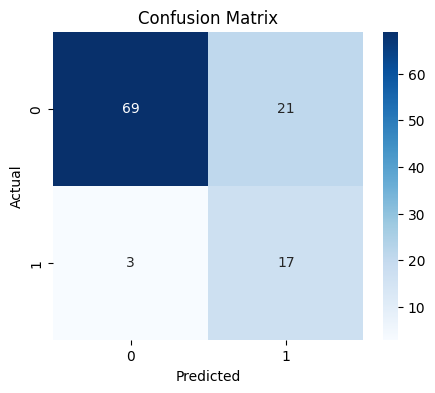

In [42]:
# Confusion matrix (print and plot)
cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix:\n", cm)

import seaborn as sns
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[0, 1], yticklabels=[0, 1])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

`Plot ROC curve`

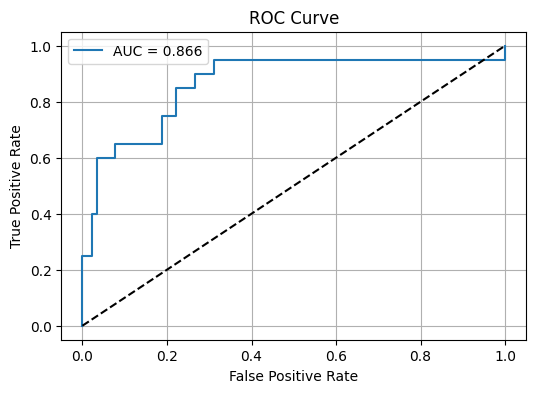

In [43]:
# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.show()

`Calibration & thresholding (practical for clinical decision)`

In [44]:
from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(y_test, y_proba, n_bins=10)

threshold = 0.4
y_pred_thresh = (y_proba >= threshold).astype(int)
print("Metrics at threshold", threshold)
print("Precision:", precision_score(y_test, y_pred_thresh))
print("Recall:", recall_score(y_test, y_pred_thresh))

Metrics at threshold 0.4
Precision: 0.4186046511627907
Recall: 0.9


In [45]:
import joblib
joblib.dump(clf_pipeline, "weather_logreg_pipeline.joblib")

['weather_logreg_pipeline.joblib']

`Quick single_day prediction`

In [46]:
# Build a sample patient (use original feature names)
sample = pd.DataFrame([{
    "MinTemp": 8, "MaxTemp": 24.3, "Rainfall": 0, "Evaporation": 3.4,
    "Sunshine": 6.3, "WindGustDir": "NW", "WindGustSpeed": 30,
    "WindDir9am": "SW", "WindDir3pm": "NW", "WindSpeed9am": 6,
    "WindSpeed3pm": 20, "Humidity9am": 68, "Humidity3pm": 29,
    "Pressure9am": 1019.7, "Pressure3pm": 1015, "Cloud9am": 7,
    "Cloud3pm": 7, "Temp9am": 14.4, "Temp3pm": 23.6,
    "RainToday": "No"
}])

proba = clf_pipeline.predict_proba(sample)[0][1]
predicted_class = int(proba >= 0.5)
print("Predicted probability of rain tomorrow:", round(proba, 3))
print("Predicted class (0=No,1=Yes):", predicted_class)

Predicted probability of rain tomorrow: 0.623
Predicted class (0=No,1=Yes): 1
